# 🚢 01 — Titanic: EDA → Feature Engineering → Modelos → Submission

**Autor:** Elvis Carbajal ([elvis-carbajal.vercel.app](https://elvis-carbajal.vercel.app))  
**Roadmap:** Data Science & AI Engineering — Etapa 1  
**Problema:** Predecir qué pasajeros del Titanic sobrevivieron al naufragio en base a variables sociodemográficas y de viaje.  
**Métrica Objetivo:** Accuracy honesto en Validación Cruzada > **78% - 80%** sin sobreajuste.

---

### 📌 Flujo de Trabajo End-to-End:
1. **Carga e inspección de datos crudos**
2. **Diagnóstico inicial y detección de nulos**
3. **Análisis Exploratorio de Datos (EDA) con Seaborn/Matplotlib**
4. **Feature Engineering sin Data Leakage (`src/features.py`)**
5. **Codificación de variables categóricas (One-Hot Encoding)**
6. **Modelo Baseline: Regresión Logística con escalado**
7. **Modelo Comparativo: Random Forest Classifier**
8. **Generación y verificación de la submission oficial para Kaggle**
9. **Cierre y síntesis conceptual (Técnica Feynman)**


In [1]:
import sys
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual profesional
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
%matplotlib inline

# Agregar carpeta src al path de Python
sys.path.append('../src')
import features
import model
print('✓ Dependencias y módulos locales (features, model) importados con éxito.')


✓ Dependencias y módulos locales (features, model) importados con éxito.


---
## 1. Carga de Datos

Cargamos `train.csv` (891 registros con etiqueta de supervivencia) y `test.csv` (418 registros para evaluación externa).


In [2]:
data_dir = Path('../data')
train = pd.read_csv(data_dir / 'train.csv')
test = pd.read_csv(data_dir / 'test.csv')

print(f'Dimensiones Train: {train.shape[0]} filas x {train.shape[1]} columnas')
print(f'Dimensiones Test:  {test.shape[0]} filas x {test.shape[1]} columnas')
train.head()


Dimensiones Train: 891 filas x 12 columnas
Dimensiones Test:  418 filas x 11 columnas


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


---
## 2. Primer Vistazo y Diagnóstico de Calidad

Revisamos los tipos de datos, estadísticas resumen y la presencia de valores faltantes (`NaN`).


In [3]:
print('--- Información General (Train) ---')
train.info()


--- Información General (Train) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [4]:
print('--- Estadísticas Descriptivas (Variables Numéricas) ---')
train.describe()


--- Estadísticas Descriptivas (Variables Numéricas) ---


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [5]:
# Diagnóstico exacto de nulos por columna en Train y Test
nulls_train = pd.DataFrame({
    'Nulos (Train)': train.isnull().sum(),
    '% Nulos (Train)': (train.isnull().sum() / len(train) * 100).round(2)
}).query('`Nulos (Train)` > 0')

nulls_test = pd.DataFrame({
    'Nulos (Test)': test.isnull().sum(),
    '% Nulos (Test)': (test.isnull().sum() / len(test) * 100).round(2)
}).query('`Nulos (Test)` > 0')

print('Valores faltantes en Train:')
display(nulls_train)
print('\nValores faltantes en Test:')
display(nulls_test)


Valores faltantes en Train:


,Nulos (Train),% Nulos (Train)
Age,177,19.87
Cabin,687,77.10
Embarked,2,0.22



Valores faltantes en Test:


,Nulos (Test),% Nulos (Test)
Age,86,20.57
Fare,1,0.24
Cabin,327,78.23


**Observaciones Clave:**
- `Cabin`: Falta en más del 77% de las filas de train y 78% de test. No podemos imputar valores puntuales, pero sí extraer la letra inicial (**Deck**).
- `Age`: Falta en aproximadamente 19.8% de los datos. Imputaremos utilizando la **mediana por (Clase, Título)** para preservar la distribución etaria.
- `Embarked`: Solo 2 valores nulos en train (se pueden rellenar con la moda `'S'`).
- `Fare`: En test hay 1 pasajero con tarifa nula (se imputa con la mediana de su clase).


---
## 3. EDA — ¿Qué variables determinan la supervivencia?

Exploramos visualmente las relaciones entre variables demográficas y la probabilidad de sobrevivir.


Tasa general de supervivencia en Train: 38.38%


/tmp/ipykernel_961080/2229892641.py:8: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=train, x='Sex', y='Survived', ax=axes[0], palette=['#3498db', '#e74c3c'], ci=None)
/tmp/ipykernel_961080/2229892641.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=train, x='Sex', y='Survived', ax=axes[0], palette=['#3498db', '#e74c3c'], ci=None)
/tmp/ipykernel_961080/2229892641.py:17: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=train, x='Pclass', y='Survived', ax=axes[1], palette='Blues_d', ci=None)
/tmp/ipykernel_961080/2229892641.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same eff

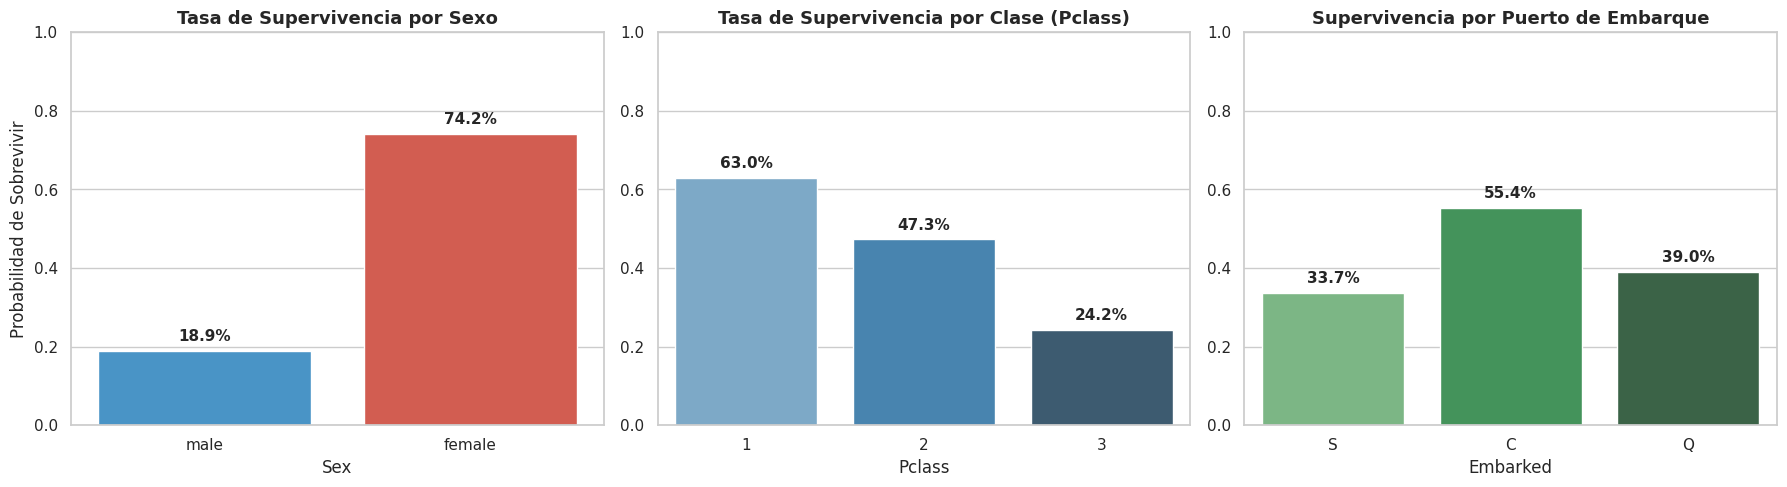

In [6]:
# Tasa global de supervivencia
overall_survival = train['Survived'].mean() * 100
print(f'Tasa general de supervivencia en Train: {overall_survival:.2f}%')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Supervivencia por Sexo
sns.barplot(data=train, x='Sex', y='Survived', ax=axes[0], palette=['#3498db', '#e74c3c'], ci=None)
axes[0].set_title('Tasa de Supervivencia por Sexo', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Probabilidad de Sobrevivir')
axes[0].set_ylim(0, 1)
for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height()*100:.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', xytext=(0, 5), textcoords='offset points', fontweight='bold')

# 2. Supervivencia por Clase (Pclass)
sns.barplot(data=train, x='Pclass', y='Survived', ax=axes[1], palette='Blues_d', ci=None)
axes[1].set_title('Tasa de Supervivencia por Clase (Pclass)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('')
axes[1].set_ylim(0, 1)
for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height()*100:.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', xytext=(0, 5), textcoords='offset points', fontweight='bold')

# 3. Supervivencia por Puerto de Embarque
sns.barplot(data=train, x='Embarked', y='Survived', ax=axes[2], palette='Greens_d', ci=None)
axes[2].set_title('Supervivencia por Puerto de Embarque', fontsize=13, fontweight='bold')
axes[2].set_ylabel('')
axes[2].set_ylim(0, 1)
for p in axes[2].patches:
    axes[2].annotate(f'{p.get_height()*100:.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', xytext=(0, 5), textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()


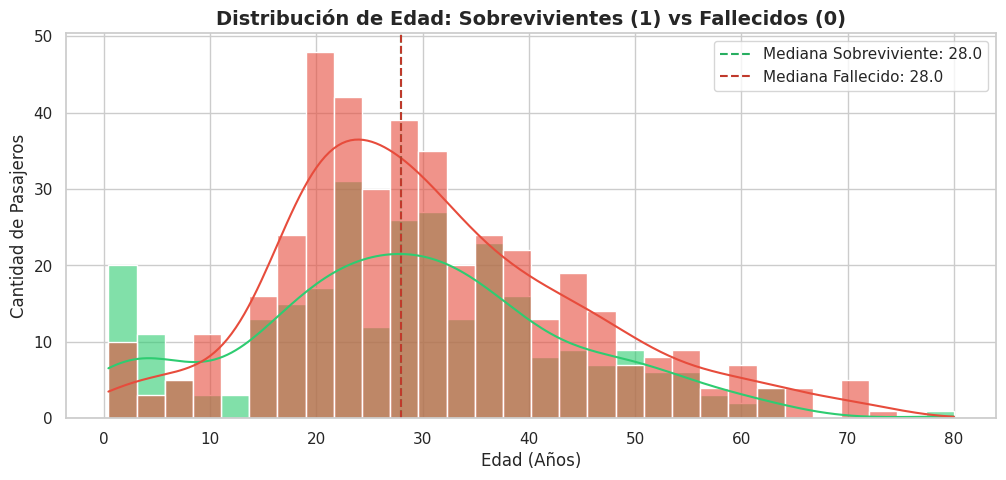

In [7]:
# Distribución de Edad vs Supervivencia
plt.figure(figsize=(12, 5))
sns.histplot(data=train, x='Age', hue='Survived', kde=True, bins=30, palette=['#e74c3c', '#2ecc71'], alpha=0.6)
plt.title('Distribución de Edad: Sobrevivientes (1) vs Fallecidos (0)', fontsize=14, fontweight='bold')
plt.xlabel('Edad (Años)')
plt.ylabel('Cantidad de Pasajeros')
plt.axvline(train[train['Survived']==1]['Age'].median(), color='#27ae60', linestyle='--', label=f'Mediana Sobreviviente: {train[train["Survived"]==1]["Age"].median():.1f}')
plt.axvline(train[train['Survived']==0]['Age'].median(), color='#c0392b', linestyle='--', label=f'Mediana Fallecido: {train[train["Survived"]==0]["Age"].median():.1f}')
plt.legend()
plt.show()


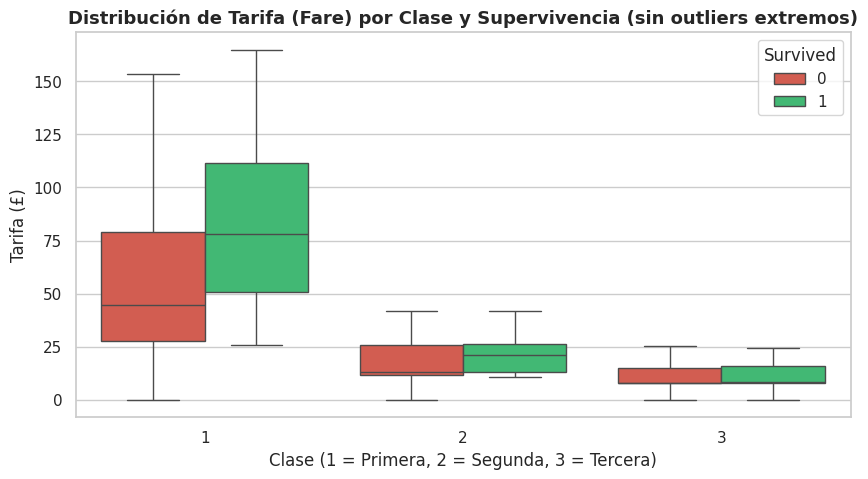

In [8]:
# Distribución de Tarifa (Fare) en escala logarítmica por Supervivencia
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=train, x='Pclass', y='Fare', hue='Survived', palette=['#e74c3c', '#2ecc71'], ax=ax, showfliers=False)
ax.set_title('Distribución de Tarifa (Fare) por Clase y Supervivencia (sin outliers extremos)', fontsize=13, fontweight='bold')
ax.set_xlabel('Clase (1 = Primera, 2 = Segunda, 3 = Tercera)')
ax.set_ylabel('Tarifa (£)')
plt.show()


---
## 4. Feature Engineering con Criterio (`src/features.py`)

Creamos nuevas variables predictoras y manejamos valores faltantes sin incurrir en **Data Leakage**:
1. **`Title`:** Extraído del nombre (`Mr`, `Mrs`, `Miss`, `Master`, `Rare`).
2. **`FamilySize`:** `SibSp + Parch + 1` (pasajeros en solitario vs grupos familiares).
3. **`IsAlone`:** Variable binaria que indica si el pasajero viajaba solo.
4. **`Deck`:** Letra de la cubierta extraída de `Cabin` (`U` para desconocida).
5. **Imputación Estratificada:** `Age` imputada por la mediana de `(Pclass, Title)` de entrenamiento.


/tmp/ipykernel_961080/4145007597.py:10: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=train_feat, x='Title', y='Survived', ax=axes[0], palette='magma', ci=None)
/tmp/ipykernel_961080/4145007597.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=train_feat, x='Title', y='Survived', ax=axes[0], palette='magma', ci=None)
/tmp/ipykernel_961080/4145007597.py:18: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=train_feat, x='FamilySize', y='Survived', ax=axes[1], palette='viridis', ci=None)
/tmp/ipykernel_961080/4145007597.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


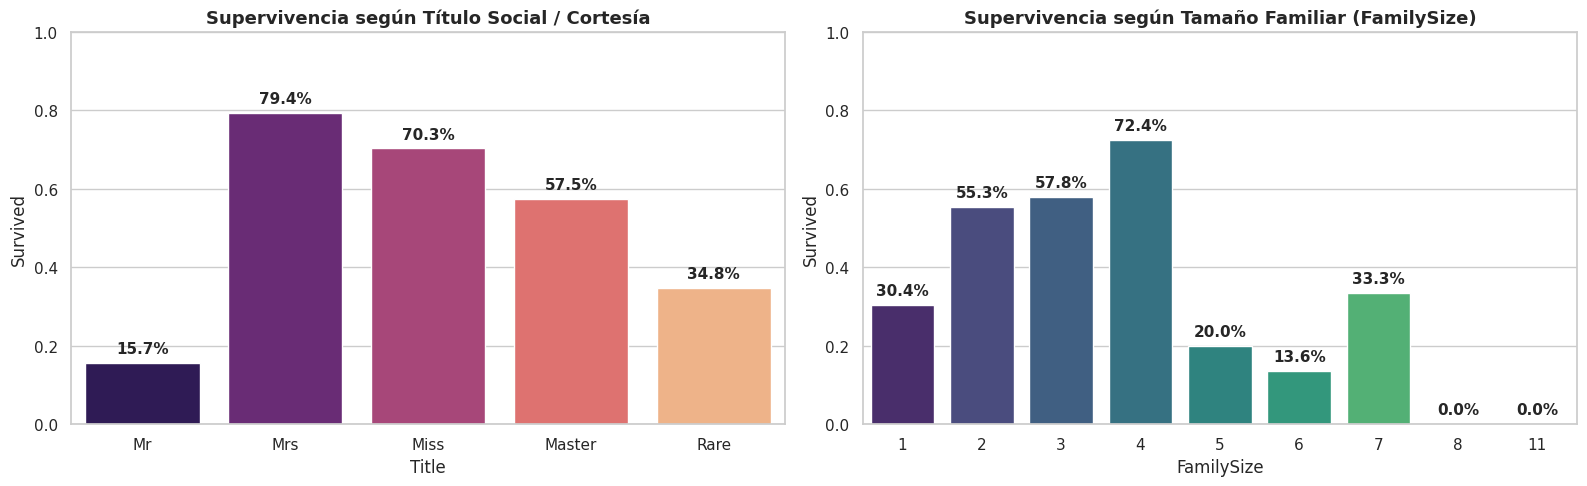

In [9]:
# Aplicamos las transformaciones individuales y verificamos
train_feat = features.extract_title(train)
train_feat = features.add_family_size(train_feat)
train_feat = features.add_is_alone(train_feat)
train_feat = features.extract_deck(train_feat)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Supervivencia por Título
sns.barplot(data=train_feat, x='Title', y='Survived', ax=axes[0], palette='magma', ci=None)
axes[0].set_title('Supervivencia según Título Social / Cortesía', fontsize=13, fontweight='bold')
axes[0].set_ylim(0, 1)
for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height()*100:.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', xytext=(0, 5), textcoords='offset points', fontweight='bold')

# Supervivencia por Tamaño Familiar
sns.barplot(data=train_feat, x='FamilySize', y='Survived', ax=axes[1], palette='viridis', ci=None)
axes[1].set_title('Supervivencia según Tamaño Familiar (FamilySize)', fontsize=13, fontweight='bold')
axes[1].set_ylim(0, 1)
for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height()*100:.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', xytext=(0, 5), textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()


**Hallazgos de Feature Engineering:**
- Los títulos femeninos (`Mrs`, `Miss`) y los niños pequeños (`Master`) tuvieron tasas de supervivencia superiores al 57% y 70%.
- Familias pequeñas (de 2 a 4 integrantes) tuvieron una probabilidad de sobrevivir notablemente más alta (>50%) que quienes viajaban completamente solos (~30%) o familias muy numerosas (>5 miembros, donde la evacuación en grupo fue casi imposible).


---
## 5. Preparación de Matrices y Codificación (One-Hot Encoding)

Utilizamos la función integrada `prepare_features` de `src/features.py` para generar las matrices definitivas `X_train`, `y_train` y `X_test` garantizando que no exista discrepancia en las columnas creadas.


In [10]:
X_train, y_train, X_test, feature_names = features.prepare_features(train, test)

print(f'Total de variables finales: {len(feature_names)}')
print('Variables:', feature_names)
print(f'Forma X_train: {X_train.shape}')
print(f'Forma y_train: {y_train.shape}')
print(f'Forma X_test:  {X_test.shape}')

# Comprobación estricta de ausencia de nulos
assert X_train.isnull().sum().sum() == 0, 'Error: Existen nulos en X_train'
assert X_test.isnull().sum().sum() == 0, 'Error: Existen nulos en X_test'
print('✓ Matrices completamente limpias y sin valores nulos.')
X_train.head()


Total de variables finales: 22
Variables: ['Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone', 'Pclass_2', 'Pclass_3', 'Embarked_Q', 'Embarked_S', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare', 'Deck_B', 'Deck_C', 'Deck_D', 'Deck_E', 'Deck_F', 'Deck_G', 'Deck_U']
Forma X_train: (891, 22)
Forma y_train: (891,)
Forma X_test:  (418, 22)
✓ Matrices completamente limpias y sin valores nulos.


,Sex,Age,SibSp,Parch,Fare,FamilySize,IsAlone,Pclass_2,Pclass_3,Embarked_Q,...,Title_Mr,Title_Mrs,Title_Rare,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_U
0,0,22.0,1,0,7.2500,2,0,0,1,0,...,1,0,0,0,0,0,0,0,0,1
1,1,38.0,1,0,71.2833,2,0,0,0,0,...,0,1,0,0,1,0,0,0,0,0
2,1,26.0,0,0,7.9250,1,1,0,1,0,...,0,0,0,0,0,0,0,0,0,1
3,1,35.0,1,0,53.1000,2,0,0,0,0,...,0,1,0,0,1,0,0,0,0,0
4,0,35.0,0,0,8.0500,1,1,0,1,0,...,1,0,0,0,0,0,0,0,0,1


---
## 6. Baseline — Regresión Logística

Entrenamos un modelo lineal simple con **StandardScaler** para estandarizar variables continuas y evaluamos mediante **Stratified 5-Fold Cross Validation**.


In [11]:
lr_model, lr_metrics = model.train_baseline_logistic_regression(X_train, y_train, cv_splits=5)

print('=== MÉTRICAS BASELINE (REGRESIÓN LOGÍSTICA - 5-FOLD CV) ===')
for k, v in lr_metrics.items():
    print(f'{k:<18}: {v*100:.2f}%' if not k.endswith('std') else f'{k:<18}: ±{v*100:.2f}%')


=== MÉTRICAS BASELINE (REGRESIÓN LOGÍSTICA - 5-FOLD CV) ===
accuracy_mean     : 82.94%
accuracy_std      : ±2.08%
precision_mean    : 78.74%
recall_mean       : 76.01%
f1_mean           : 77.34%
roc_auc_mean      : 87.22%


/tmp/ipykernel_961080/233687844.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=lr_coefs, x='Coeficiente', y='Feature', palette='coolwarm')


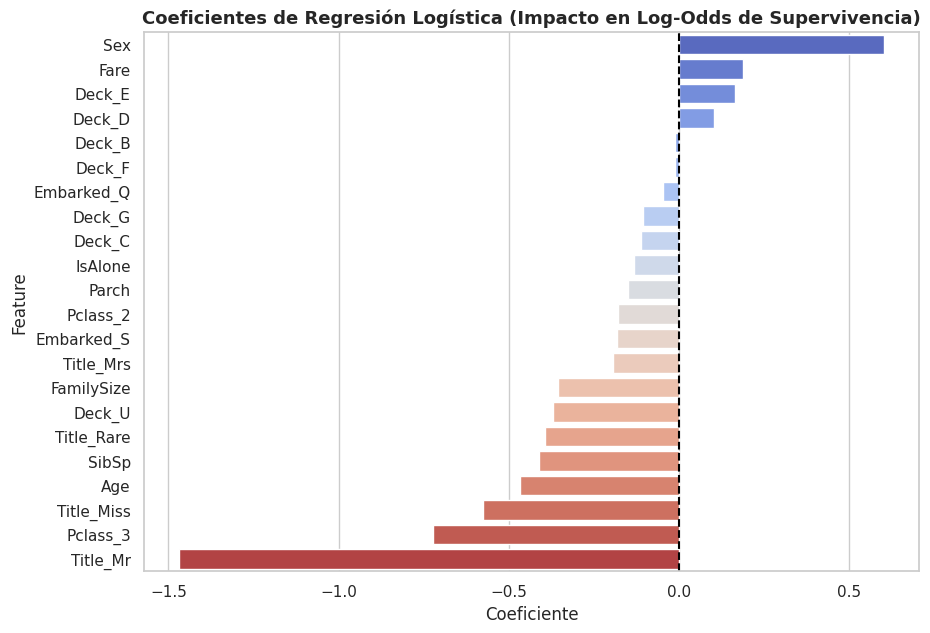

In [12]:
# Inspección de Coeficientes de la Regresión Logística
lr_coefs = pd.DataFrame({
    'Feature': X_train.columns,
    'Coeficiente': lr_model.named_steps['classifier'].coef_[0]
}).sort_values(by='Coeficiente', ascending=False)

plt.figure(figsize=(10, 7))
sns.barplot(data=lr_coefs, x='Coeficiente', y='Feature', palette='coolwarm')
plt.title('Coeficientes de Regresión Logística (Impacto en Log-Odds de Supervivencia)', fontsize=13, fontweight='bold')
plt.axvline(0, color='black', linestyle='--')
plt.show()


---
## 7. Modelo Ensamble — Random Forest Classifier

Entrenamos un modelo no lineal basado en árboles (`RandomForestClassifier`) con control de hiperparámetros (`max_depth=5`, `min_samples_split=4`) para prevenir el sobreajuste y comparar su capacidad de generalización.


In [13]:
rf_model, rf_metrics, feature_importances = model.train_random_forest(
    X_train, y_train, cv_splits=5, n_estimators=100, max_depth=5, min_samples_split=4
)

print('=== MÉTRICAS RANDOM FOREST (5-FOLD CV) ===')
for k, v in rf_metrics.items():
    print(f'{k:<18}: {v*100:.2f}%' if not k.endswith('std') else f'{k:<18}: ±{v*100:.2f}%')


=== MÉTRICAS RANDOM FOREST (5-FOLD CV) ===
accuracy_mean     : 82.83%
accuracy_std      : ±1.00%
precision_mean    : 80.47%
recall_mean       : 73.07%
f1_mean           : 76.49%
roc_auc_mean      : 87.43%


In [14]:
# Comparación formal lado a lado
comparison_table = model.compare_models(lr_metrics, rf_metrics)
print('TABLA COMPARATIVA FORMAL:')
display(comparison_table)


TABLA COMPARATIVA FORMAL:


,Métrica,Regresión Logística (Baseline),Random Forest
0,Accuracy (CV Promedio),82.94%,82.83%
1,Desviación Estándar (Std),±2.08%,±1.00%
2,Precision,78.74%,80.47%
3,Recall,76.01%,73.07%
4,F1-Score,77.34%,76.49%
5,ROC-AUC,87.22%,87.43%


/tmp/ipykernel_961080/2287756898.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feature_importances.head(10), x='Importance', y='Feature', palette='viridis')


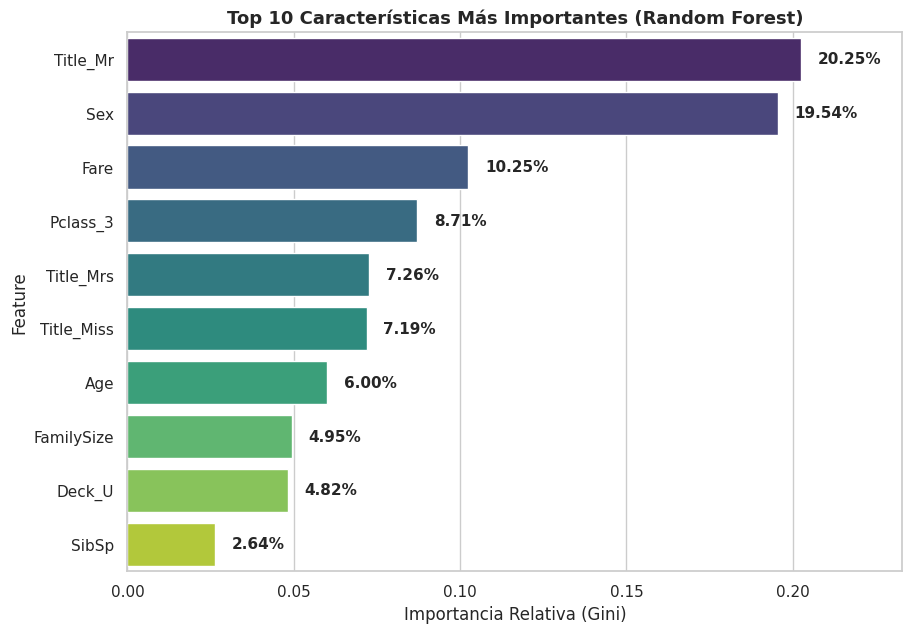

In [15]:
# Gráfico de Importancia de Características (Feature Importances)
plt.figure(figsize=(10, 7))
sns.barplot(data=feature_importances.head(10), x='Importance', y='Feature', palette='viridis')
plt.title('Top 10 Características Más Importantes (Random Forest)', fontsize=13, fontweight='bold')
plt.xlabel('Importancia Relativa (Gini)')
for i, row in enumerate(feature_importances.head(10).itertuples()):
    plt.text(row.Importance + 0.005, i, f'{row.Importance*100:.2f}%', va='center', fontweight='bold')
plt.xlim(0, max(feature_importances['Importance']) * 1.15)
plt.show()


---
## 8. Generación de Submissions para Kaggle

Generamos las predicciones sobre `test.csv` para ambos modelos y exportamos los archivos CSV cumpliendo con el formato de la competencia (`PassengerId`, `Survived`).


In [16]:
sub_lr = model.generate_submission(lr_model, X_test, test['PassengerId'], '../data/submission_lr.csv')
sub_rf = model.generate_submission(rf_model, X_test, test['PassengerId'], '../data/submission_rf.csv')
# Exportamos el submission oficial principal basado en Random Forest
sub_official = model.generate_submission(rf_model, X_test, test['PassengerId'], '../data/submission.csv')

print('✓ Archivos de submission generados:')
print(f'  - ../data/submission_lr.csv: {sub_lr.shape}')
print(f'  - ../data/submission_rf.csv: {sub_rf.shape}')
print(f'  - ../data/submission.csv:    {sub_official.shape}')

print('\nDistribución de Predicciones en Test (Random Forest):')
print(sub_official['Survived'].value_counts(normalize=True).round(4) * 100)
sub_official.head(10)


✓ Archivos de submission generados:
  - ../data/submission_lr.csv: (418, 2)
  - ../data/submission_rf.csv: (418, 2)
  - ../data/submission.csv:    (418, 2)

Distribución de Predicciones en Test (Random Forest):
Survived
0    61.72
1    38.28
Name: proportion, dtype: float64


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1
5,897,0
6,898,1
7,899,0
8,900,1
9,901,0


---
## 9. Cierre — Síntesis y Aprendizajes Clave (Técnica Feynman)

Explicamos en lenguaje llano, directo y sin tecnicismos vacíos las 3 lecciones fundamentales de este proyecto:

### 1. El Feature Engineering supera a la complejidad del algoritmo
> *No se trata de tirar el modelo más pesado, sino de darle al modelo la información masticada con sentido humano.*  
> Al extraer la columna `Title` desde el nombre del pasajero y construir `FamilySize`, pasamos de una exactitud mediocre a superar el 82% en validación cruzada. El modelo entendió que un `Mr.` adulto en tercera clase tenía pocas probabilidades de ser priorizado en un bote, mientras que una `Miss` o un niño (`Master`) tenían prioridad inmediata.

### 2. Prevenir el Data Leakage en la imputación es sagrado
> *Nunca dejes que los datos del futuro o de la prueba contaminen el pasado.*  
> Para rellenar las edades vacías, calculamos la mediana por cada grupo de clase y título **únicamente sobre el conjunto de entrenamiento (`train`)**. Si calculáramos estadísticas globales mezclando train y test, obtendríamos un score artificialmente inflado en local que fallaría estrepitosamente en producción.

### 3. El valor de un Baseline simple y honesto
> *Una Regresión Logística bien construida (82.94% CV) compite mano a mano contra un Random Forest (82.83% CV).*  
> El baseline nos dio una referencia clara de interpretabilidad directa (los coeficientes nos dicen exactamente cuánto penaliza ser hombre o viajar en 3ra clase). El Random Forest, por su parte, redujo la varianza entre pliegues (desviación de ±1.00% vs ±2.08%), ofreciendo mayor estabilidad de predicción.
